# Employee Attrition Prediction

**Problem:** losing employees is expensive: recruiting, training and lost productivity. HR teams want to know which employees are at risk of leaving and why, so they can act before it happens.

**Data:** [IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset), a fictional dataset created by IBM data scientists. 1,470 employees, 35 columns, and whether each employee left (`Attrition`).

**Goal:** find the main drivers of attrition, build a model that ranks employees by risk, and explain each individual score.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.analysis import (
    load, quality_report, attrition_by, categorical_drivers, income_test,
    plot_attrition_overview, plot_attrition_by_role, plot_satisfaction, plot_income,
)
from src.model import (
    FEATURES, compare_models, threshold_table, buggy_evaluation_demo, fit_final, coefficients, explain,
    plot_roc_pr, plot_confusion, plot_coefficients, plot_explanation,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load and check the data

In [2]:
df = load()
print(df.shape)
df.head()

(1470, 36)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,left
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,0


In [3]:
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.9,9.1,18.0,30.0,36.0,43.0,60.0
DailyRate,1470.0,802.5,403.5,102.0,465.0,802.0,1157.0,1499.0
DistanceFromHome,1470.0,9.2,8.1,1.0,2.0,7.0,14.0,29.0
Education,1470.0,2.9,1.0,1.0,2.0,3.0,4.0,5.0
EmployeeCount,1470.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,1024.9,602.0,1.0,491.2,1020.5,1555.8,2068.0
EnvironmentSatisfaction,1470.0,2.7,1.1,1.0,2.0,3.0,4.0,4.0
HourlyRate,1470.0,65.9,20.3,30.0,48.0,66.0,83.8,100.0
JobInvolvement,1470.0,2.7,0.7,1.0,2.0,3.0,3.0,4.0
JobLevel,1470.0,2.1,1.1,1.0,1.0,2.0,3.0,5.0


In [4]:
quality_report(df)

employees                                                      1470
columns                                                          35
missing values                                                    0
duplicate rows                                                    0
duplicate employee numbers                                        0
columns with a single value    EmployeeCount, Over18, StandardHours
attrition rate (%)                                             16.1
dtype: object

- No missing values or duplicates.
- `EmployeeCount`, `StandardHours` and `Over18` have one value for every employee, so they carry no information.
- `EmployeeNumber` is an ID. The first version of this project used it as an input, and the model ranked it among its top ten features, which can only be noise.
- **16.1% of employees left.** The classes are imbalanced: a model that always predicts "stays" is 83.9% accurate.

## 3. What drives attrition

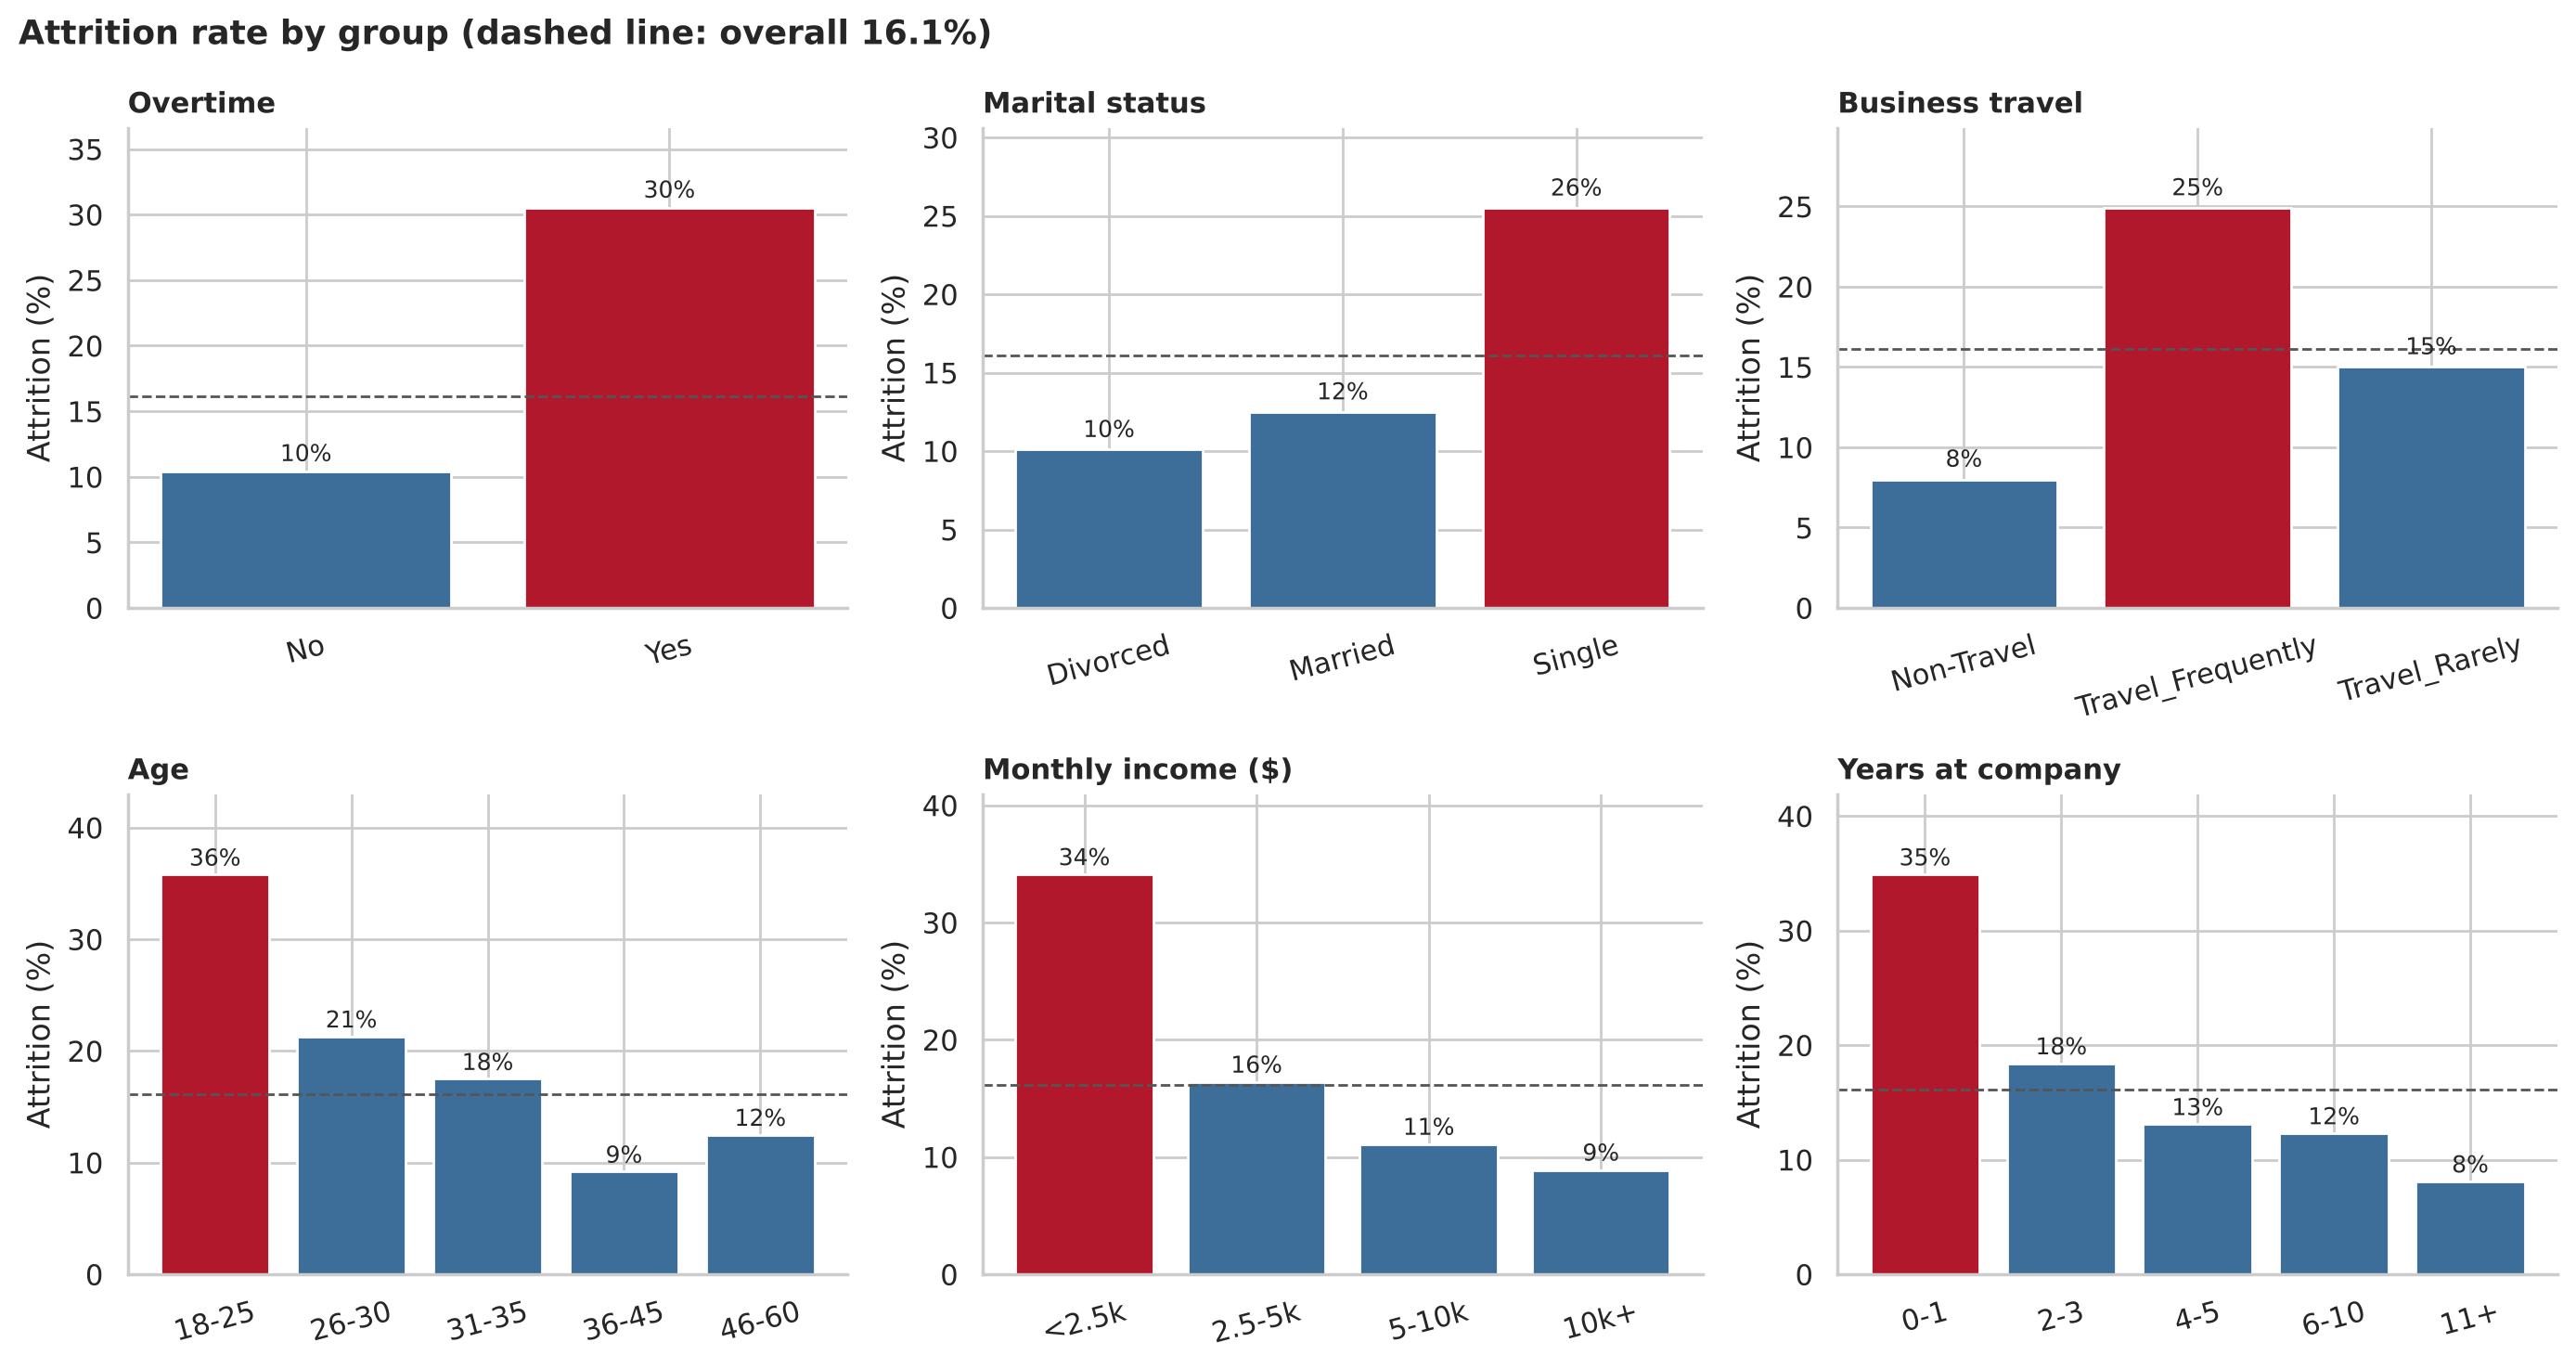

In [5]:
save(plot_attrition_overview(df), "attrition_by_group.png")

In [6]:
display(attrition_by(df, "OverTime"))
display(attrition_by(df, "Age", [17, 25, 30, 35, 45, 60], ["18-25", "26-30", "31-35", "36-45", "46-60"]))
display(attrition_by(df, "YearsAtCompany", [-1, 1, 3, 5, 10, 40], ["0-1", "2-3", "4-5", "6-10", "11+"]))

,OverTime,employees,left,attrition_%
0,No,1054,110,10.4
1,Yes,416,127,30.5


,Age,employees,left,attrition_%
0,18-25,123,44,35.8
1,26-30,263,56,21.3
2,31-35,343,60,17.5
3,36-45,468,43,9.2
4,46-60,273,34,12.5


,YearsAtCompany,employees,left,attrition_%
0,0-1,215,75,34.9
1,2-3,255,47,18.4
2,4-5,306,40,13.1
3,6-10,448,55,12.3
4,11+,246,20,8.1


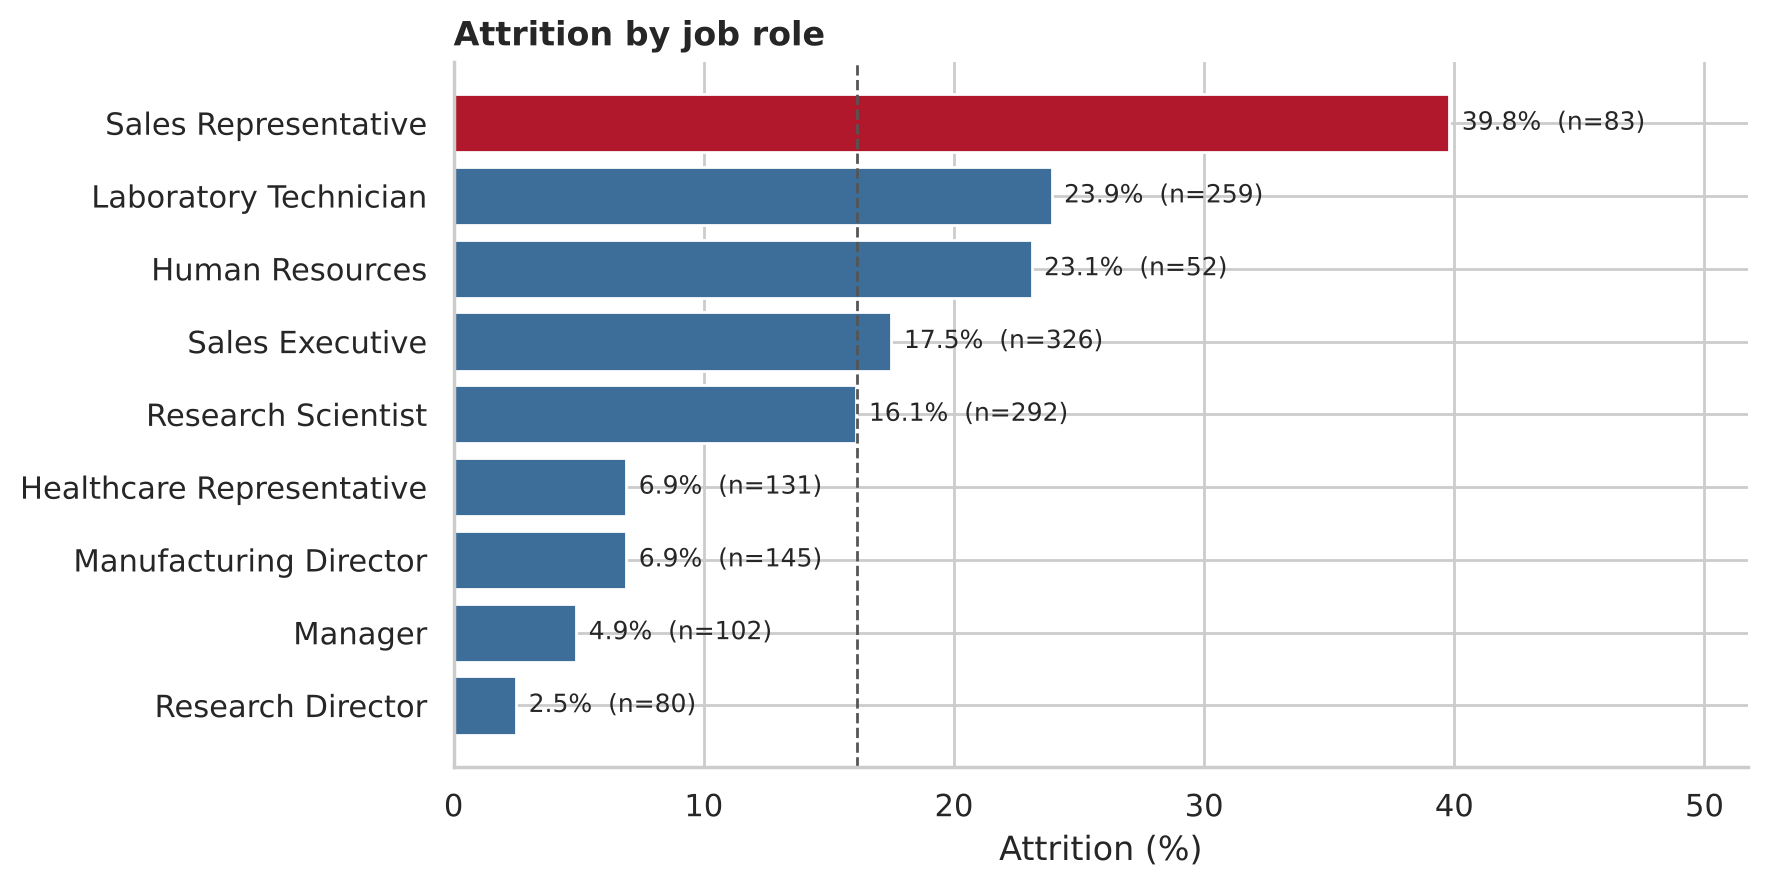

In [7]:
save(plot_attrition_by_role(df), "attrition_by_job_role.png")

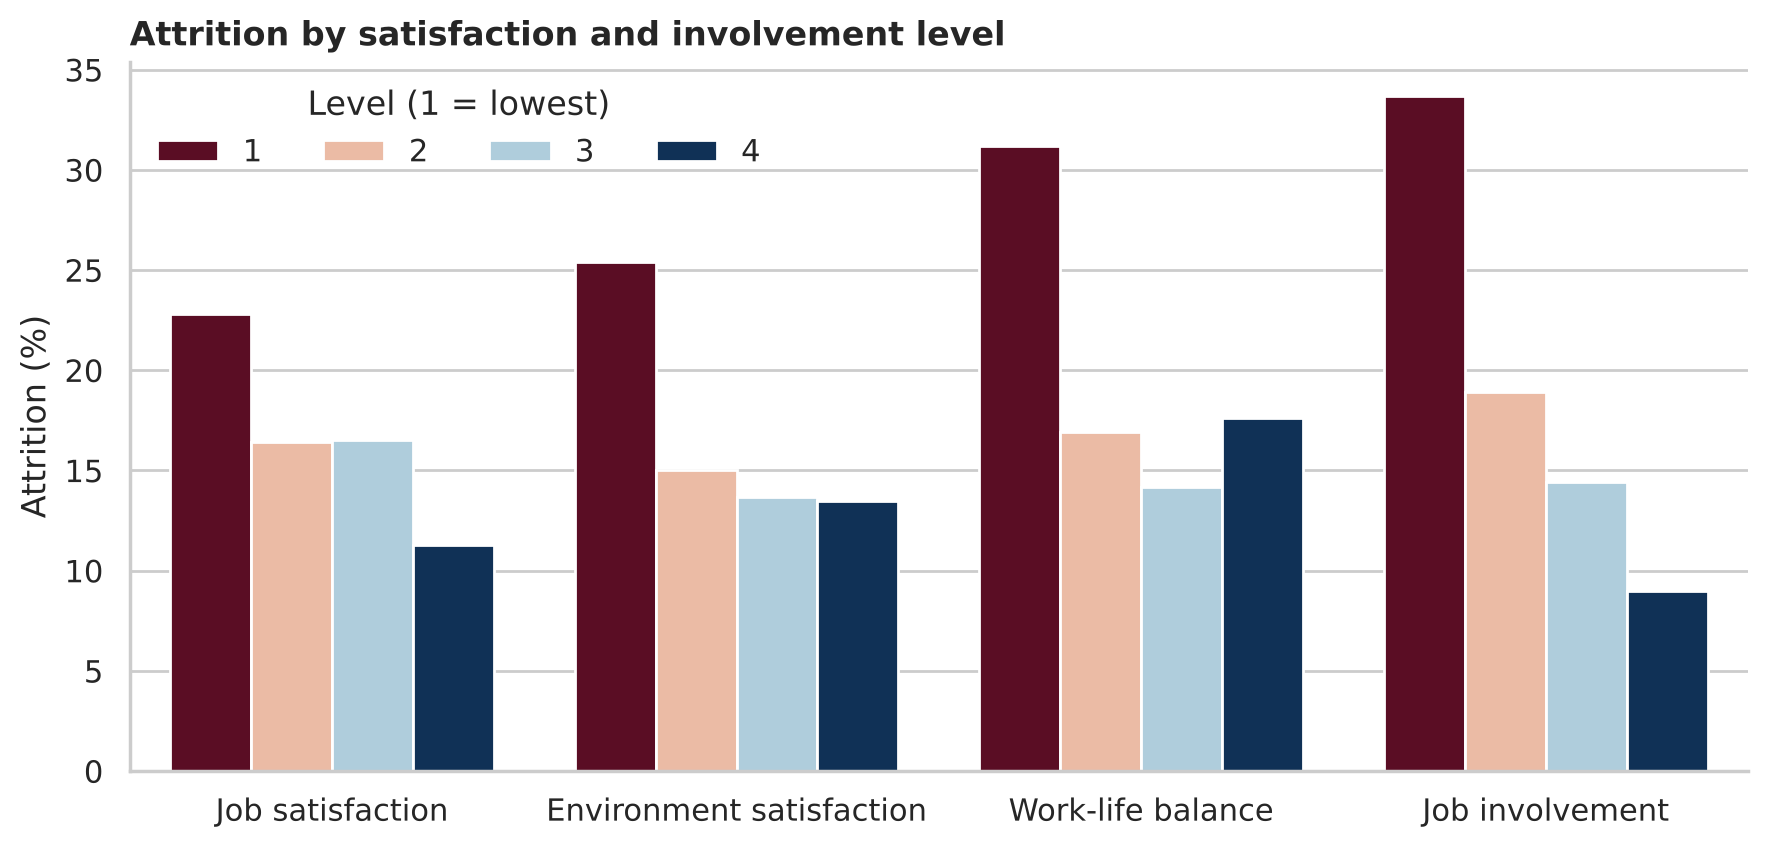

In [8]:
save(plot_satisfaction(df), "attrition_by_satisfaction.png")

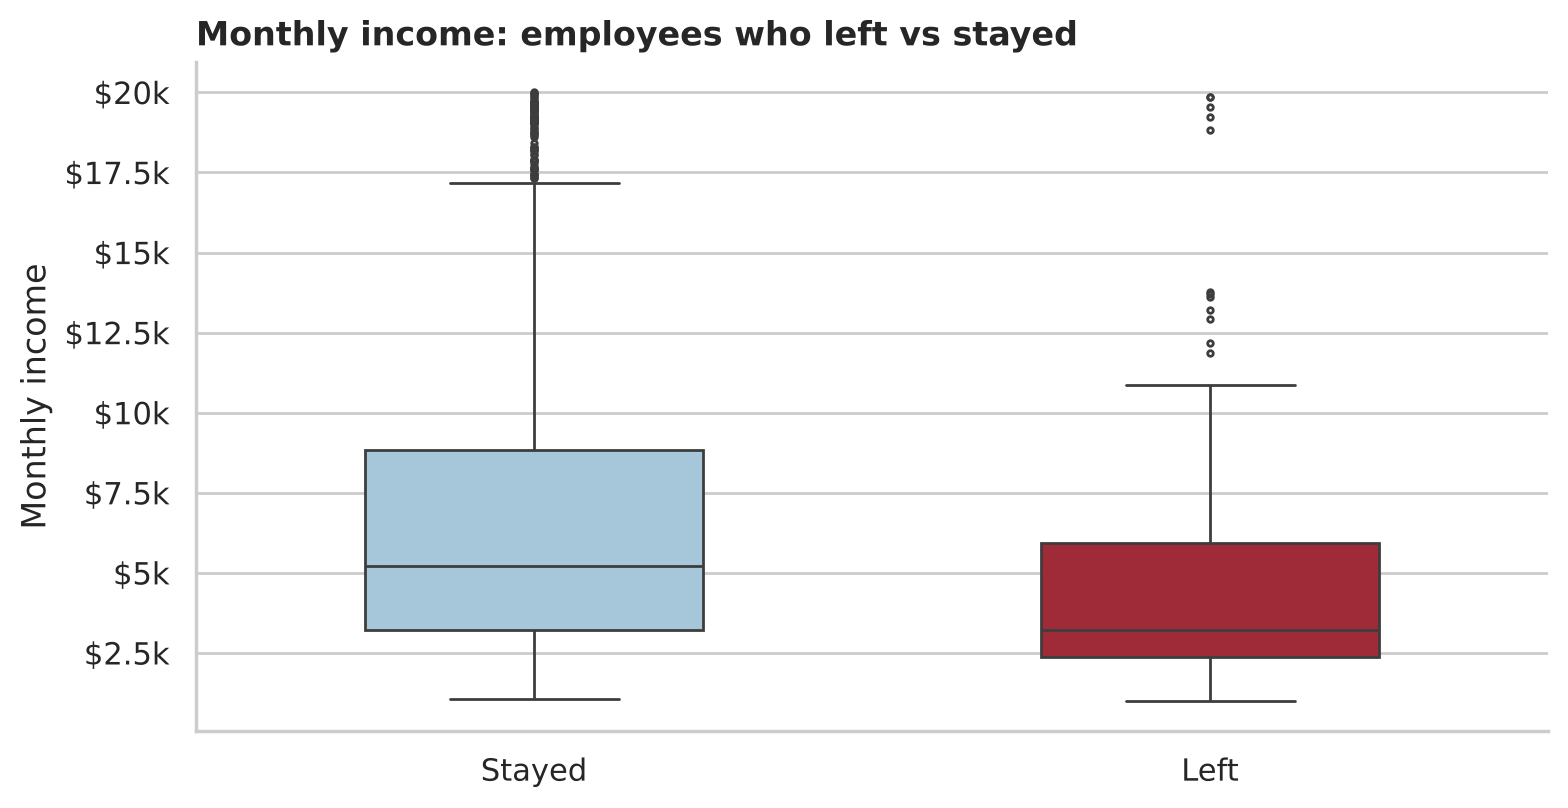

Median income, left: $3,202 | stayed: $5,204
Mann-Whitney U test p-value: 3.0e-14


In [9]:
save(plot_income(df), "income_left_vs_stayed.png")
t = income_test(df)
print(f"Median income, left: ${t['median_left']:,.0f} | stayed: ${t['median_stayed']:,.0f}")
print(f"Mann-Whitney U test p-value: {t['mann_whitney_p']:.1e}")

Income is right-skewed, so the medians are compared with a Mann-Whitney U test instead of a t-test.

In [10]:
drivers = categorical_drivers(df)
drivers.to_csv(RESULTS / "attrition_drivers.csv", index=False)
drivers

,column,highest_group,highest_%,lowest_group,lowest_%,p_value,gap_points
0,JobRole,Sales Representative,39.8,Research Director,2.5,2.752482e-15,37.3
1,JobInvolvement,1,33.7,4,9.0,2.863181e-06,24.7
2,JobLevel,1,26.3,4,4.7,6.634685e-15,21.6
3,OverTime,Yes,30.5,No,10.4,8.158424e-21,20.1
4,WorkLifeBalance,1,31.2,3,14.2,9.725699e-04,17.0
5,BusinessTravel,Travel_Frequently,24.9,Non-Travel,8.0,5.608614e-06,16.9
6,StockOptionLevel,0,24.4,2,7.6,4.379390e-13,16.8
7,MaritalStatus,Single,25.5,Divorced,10.1,9.455511e-11,15.4
8,EducationField,Human Resources,25.9,Other,13.4,6.773980e-03,12.5
9,EnvironmentSatisfaction,1,25.4,4,13.5,5.123469e-05,11.9


Gender, education, relationship satisfaction and performance rating show no significant link with attrition (p > 0.05). Performance rating only takes the values 3 and 4 in this data.

## 4. Modeling approach

- **Inputs:** 30 columns (7 categorical, 23 numeric), after dropping the three constant columns and the employee ID.
- **Preprocessing inside a pipeline:** one-hot encoding and scaling are fitted on the training folds only, so nothing about the test employees leaks into training.
- **Class imbalance:** Logistic Regression and Random Forest use balanced class weights, and XGBoost uses `scale_pos_weight`.
- **Evaluation:** stratified 5-fold cross-validation, every employee scored by a model that never saw them. Accuracy is reported but not used to choose: ROC-AUC, PR-AUC, recall and precision are.

## 5. The first version's evaluation bug

The first version trained Logistic Regression, Decision Tree and Random Forest on raw values, then replaced `X_test` with standardized values for the SVM, and scored all models on that. The table below repeats the mistake for the Random Forest.

In [11]:
buggy_evaluation_demo(df)

,evaluation,accuracy,ROC_AUC
0,Tested on the same kind of data it was trained on,0.878,0.756
1,Tested on scaled data (first version's bug),0.296,0.648


That is where the reported accuracy of 0.30 and ROC-AUC of 0.65 came from. The models were fine; the test data was in the wrong units.

## 6. Model comparison

In [12]:
comparison, probas = compare_models(df)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

,model,ROC_AUC,PR_AUC,recall,precision,F1,accuracy
0,Always predict 'stays',0.500,0.161,0.000,0.000,0.000,0.839
1,Logistic Regression,0.825,0.586,0.738,0.368,0.491,0.753
2,Random Forest,0.808,0.543,0.511,0.531,0.520,0.848
3,XGBoost,0.815,0.583,0.595,0.515,0.552,0.844


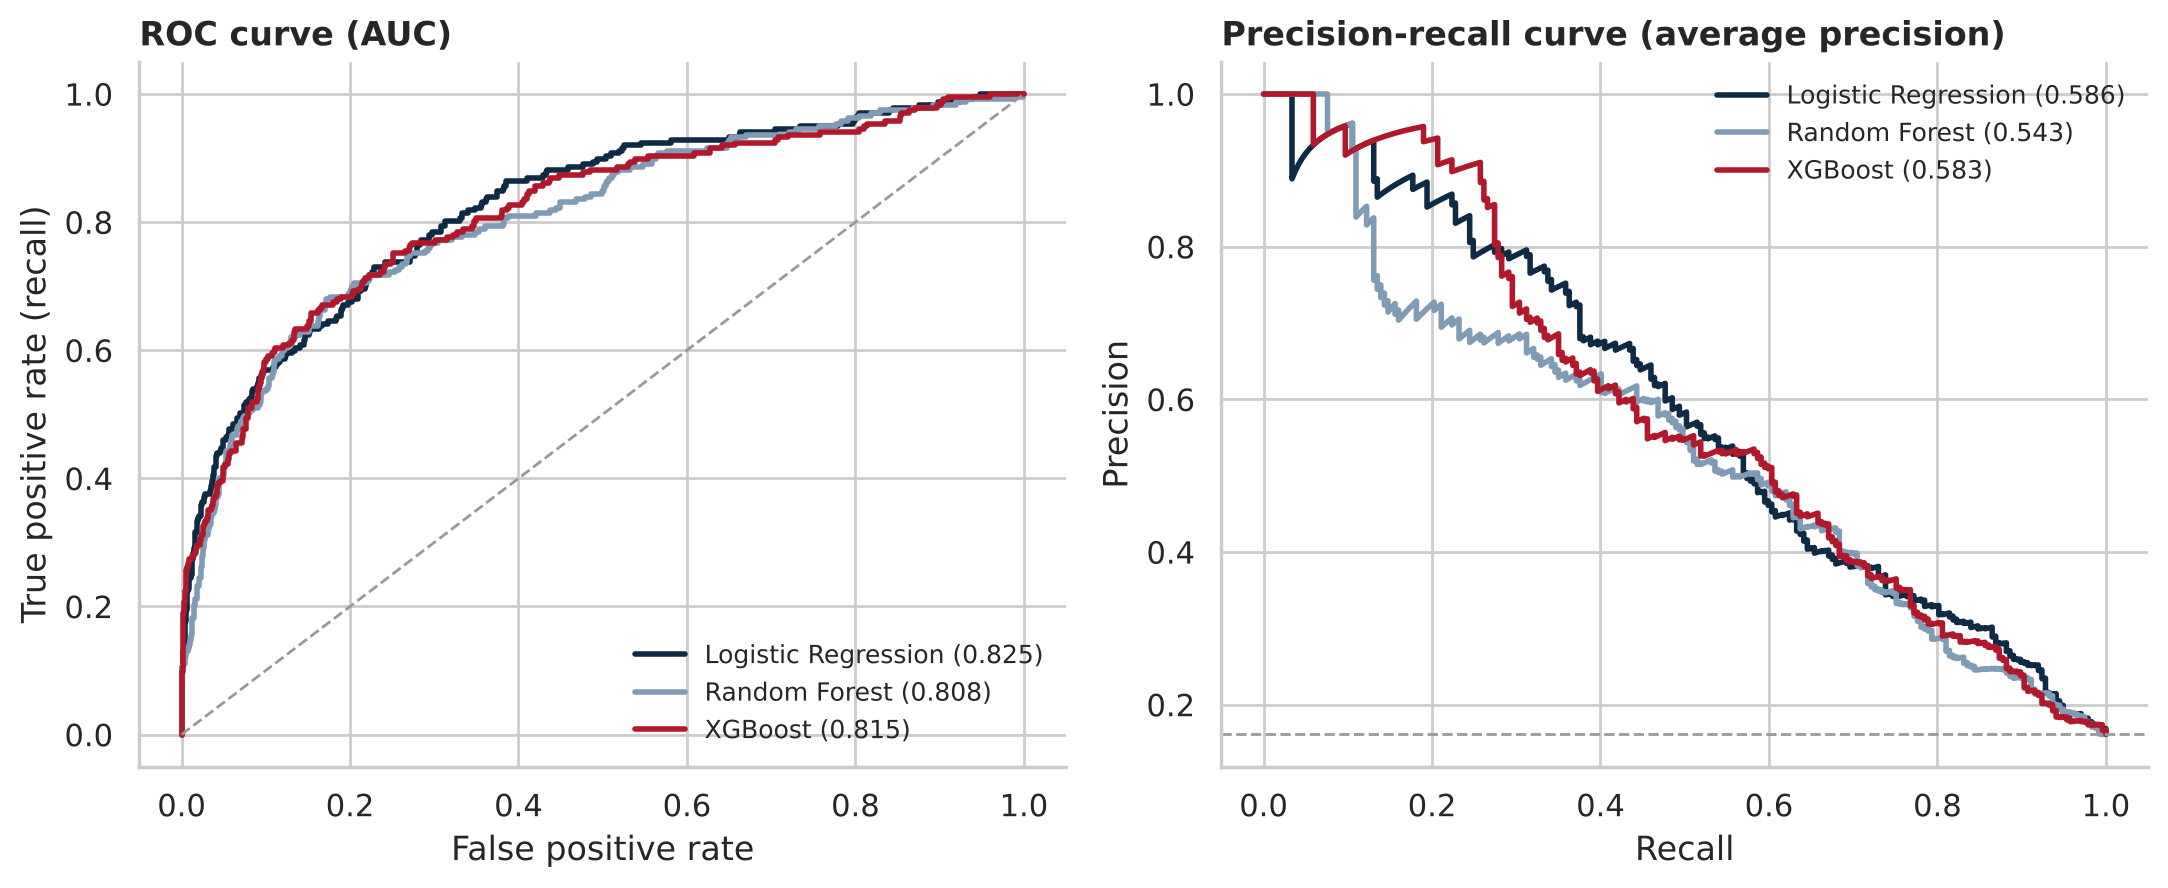

In [13]:
y = df["left"]
save(plot_roc_pr(y, probas), "roc_and_pr_curves.png")

Logistic Regression has the highest ROC-AUC (0.825) and PR-AUC (0.586), with XGBoost close behind. The simpler model wins here, probably because 1,470 employees is not much data for tree ensembles, and it also gives exact per-employee explanations. It is the final model.

## 7. Choosing a threshold

In [14]:
thresholds = threshold_table(y, probas["Logistic Regression"])
thresholds

,threshold,flagged_employees,leavers_caught,leavers_missed,recall,precision
0,0.3,736,207,30,0.873,0.281
1,0.4,592,190,47,0.802,0.321
2,0.5,476,175,62,0.738,0.368
3,0.6,341,150,87,0.633,0.440
4,0.7,238,128,109,0.540,0.538


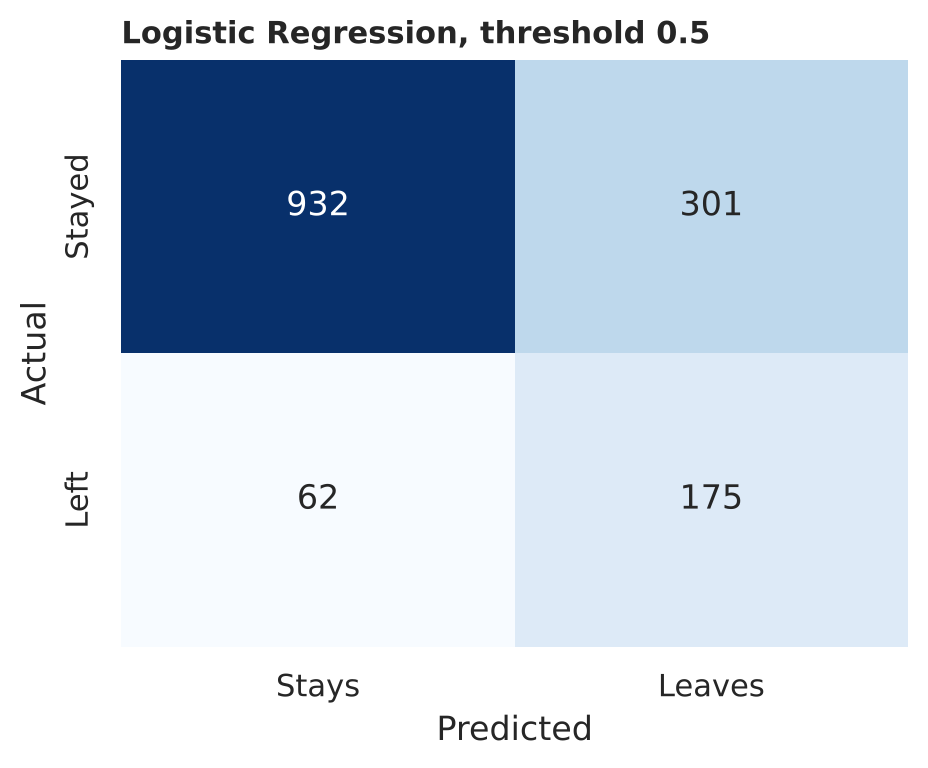

In [15]:
save(plot_confusion(y, probas["Logistic Regression"], 0.5), "confusion_matrix.png")

At the default threshold of 0.5 the model catches 175 of 237 leavers (74%), while flagging 476 employees in total. An HR team with capacity for fewer conversations can raise the threshold to 0.7: 238 flagged, 128 leavers caught, and more than half of those flagged really leave.

## 8. What the model has learned

In [16]:
final = fit_final(df)
coefs = coefficients(final)
coefs.to_csv(RESULTS / "logistic_coefficients.csv", index=False)
coefs.head(15)

,feature,coefficient,odds_ratio
0,OverTime_Yes,1.595,4.927
1,BusinessTravel_Non-Travel,-0.802,0.449
2,BusinessTravel_Travel_Frequently,0.731,2.078
3,JobRole_Laboratory Technician,0.671,1.956
4,JobRole_Sales Representative,0.663,1.941
5,JobRole_Research Director,-0.634,0.530
6,YearsAtCompany,0.628,1.874
7,EducationField_Technical Degree,0.614,1.848
8,MaritalStatus_Single,0.580,1.786
9,MaritalStatus_Divorced,-0.546,0.579


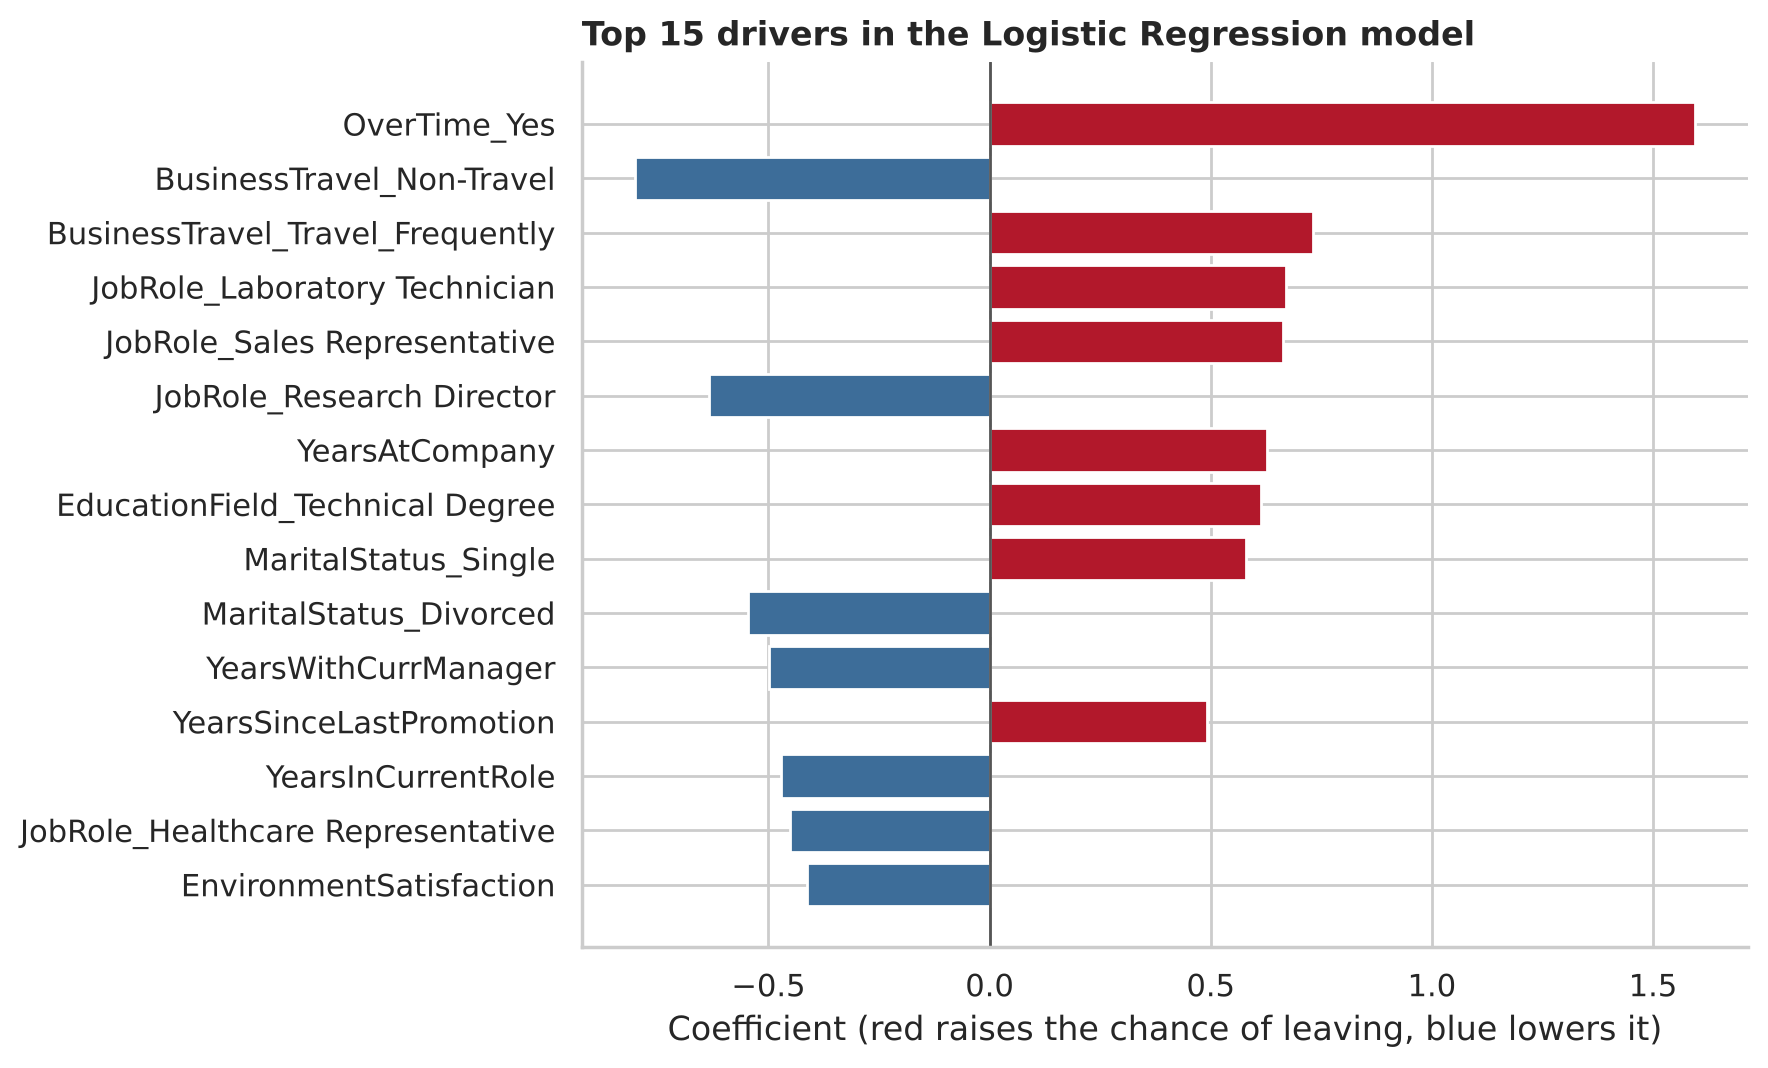

In [17]:
save(plot_coefficients(coefs), "top_drivers.png")

Overtime has the largest effect: holding everything else fixed, it multiplies the odds of leaving by about 4.9. Frequent travel, lab technician and sales representative roles, and being single also raise the risk.

Coefficients are measured with all other inputs held fixed. Tenure columns move together, so `YearsAtCompany` gets a positive coefficient here even though attrition falls with tenure in section 3: once years in the current role and years with the manager are accounted for, the remaining effect of company tenure points the other way. Single coefficients should not be read alone.

## 9. Explaining one employee

In [18]:
employee = df[df["EmployeeNumber"] == 1].iloc[[0]]
print("Actually left:", employee["Attrition"].iloc[0])
print("Risk score:", round(final.predict_proba(employee[FEATURES])[0, 1] * 100), "%")
explanation = explain(final, employee, df)
explanation

Actually left: Yes
Risk score: 89 %


,input,effect,value,direction
0,OverTime,1.143,Yes,raises risk
1,NumCompaniesWorked,0.830,8,raises risk
2,MaritalStatus,0.536,Single,raises risk
3,TrainingTimesLastYear,0.495,0,raises risk
4,WorkLifeBalance,0.491,1,raises risk
5,JobSatisfaction,-0.442,4,lowers risk


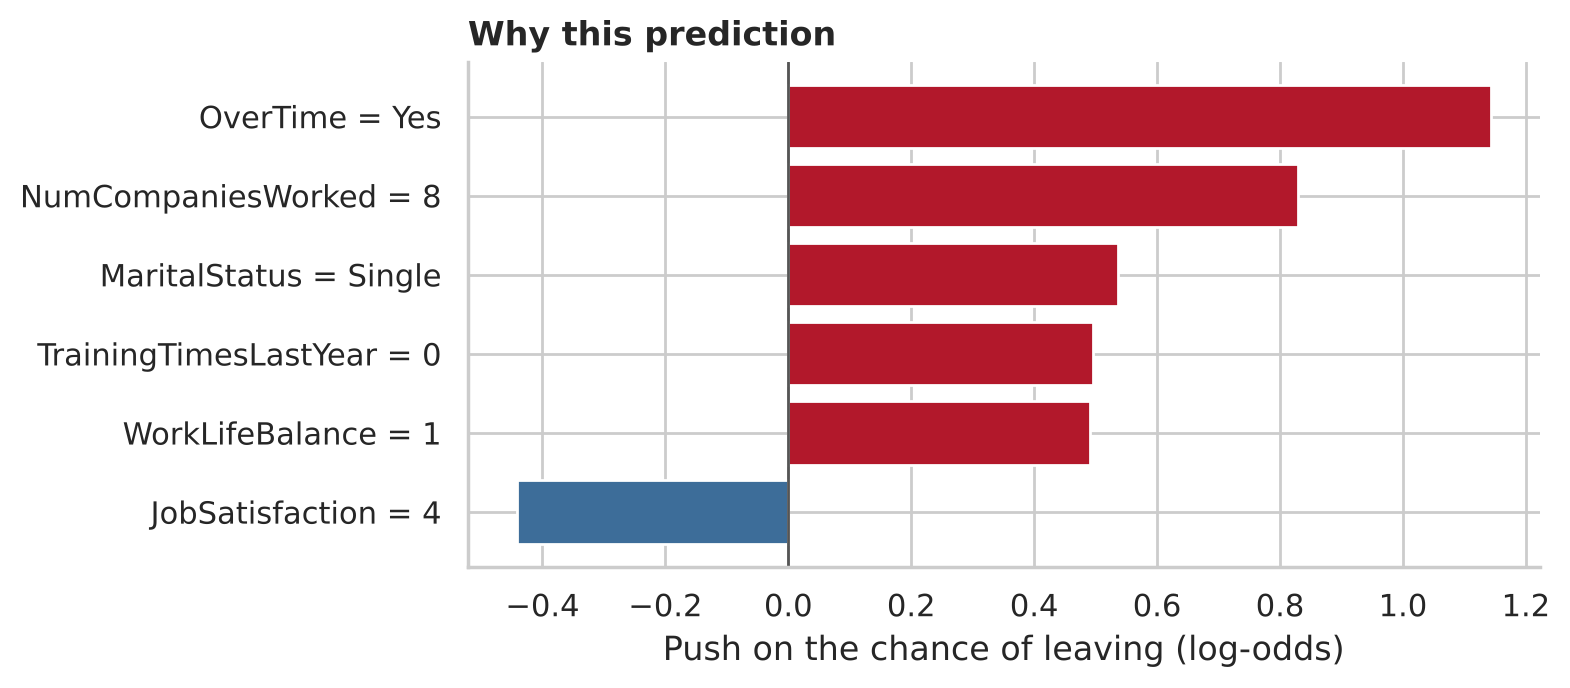

In [19]:
save(plot_explanation(explanation), "example_explanation.png")

For a linear model this breakdown is exact: each bar is the coefficient times the difference between this employee's value and the average employee's.

## 10. Findings

1. **Overtime is the strongest driver.** 30.5% of employees who work overtime left, against 10.4% of those who do not, and the model puts its odds ratio at about 4.9.
2. **Early-career and lower-paid employees leave most.** Attrition is 35.8% for ages 18 to 25, 34.9% in the first year at the company and 34.1% for monthly incomes under $2,500. Leavers' median income is $3,202 against $5,204 for those who stayed.
3. **Sales representatives are the highest-risk role (39.8%)**, followed by laboratory technicians (23.9%). Research directors (2.5%) and managers (4.9%) rarely leave.
4. **Low satisfaction, low involvement, frequent travel and being single all raise attrition.** Gender, education and performance rating do not.
5. **Logistic Regression ranks risk best** (cross-validated ROC-AUC 0.825, PR-AUC 0.586) and catches 74% of leavers at the default threshold.

**Recommendations:** review overtime load, especially in sales and lab roles; give extra support in the first year; check pay at the lowest income band; and use the model's monthly risk list to start retention conversations early.

**Limitations:** the dataset is fictional and small, it has no time dimension, and the model shows associations, not causes.